In [1]:
%reset -f

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.colors import LinearSegmentedColormap
from tensorflow.keras.models import load_model
import torch
import torch.nn as nn
import joblib
import json
from pathlib import Path
from datetime import datetime

import sys
sys.path.append("../../tools")
import architec as acht
import evaluation as eva
import prepare as prep
import functions as func

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(eva)
#importlib.reload(prep)
#importlib.reload(func)


**Switching**

In [ ]:
all_metrics = []

for rep in range(15):

    load_dir = Path(f"../../saved_models/swi_species_15fold/sp3to20_SS_transpt3_r{rep+1}")

    smodel = func.load_saved_model_SS(load_dir, device)
    sevaluator = func.TrteEvaluator(smodel)

    split_df = pd.read_csv(f"split_MD_v1/split_MD_{rep+1}.csv")
    folder_path = "../../Databases/Ver1.9/ver1.9.6_upto20"

    #-----different richness testset--------
    for rich in range(3, 21):
        narray_te = prep.load_split_dataset(
            split_df,
            folder_path,
            richness_list=[rich],
            subset="te"
        )

        # Evaluate the model on the test set
        y_te, y_prob = sevaluator.predict_array_SS(narray_te, device, sample_size=None)

        threshold = 0.3
        metrics_list = []

        for i in range(rich):
            metrics_i = eva.eval_binary(y_te[:, i], y_prob[:, i], threshold=threshold)
            metrics_i["Species"] = i
            metrics_list.append(metrics_i)

        df_metrics_species = pd.DataFrame(metrics_list)

        metrics = (
            df_metrics_species
            .drop(columns=["Species"])
            .mean().to_dict()
        )
        
        metrics["rep"] = rep + 1
        metrics["test_richness"] = rich   
        all_metrics.append(metrics)

df_metrics = pd.DataFrame(all_metrics)
df_metrics.to_pickle("switching2.pkl")


**Fluctuation**

In [ ]:
all_metrics = []

for rep in range(15):

    load_dir = Path(f"../../saved_models/fluctuation_15fold_v2/sp3to20_Fl_transpt3_r{rep+1}")

    fmodel = func.load_saved_model_MD(load_dir, device)
    fevaluator = func.TrteEvaluator(fmodel)

    split_df = pd.read_csv(f"split_fl_v2/split_fl_{rep+1}.csv")
    folder_path = "../../Databases/Ver1.9/ver1.9.6_upto20_fl"

    #-----different richness testset--------
    for rich in range(3, 21):
        narray_te = prep.load_split_dataset(
            split_df,
            folder_path,
            richness_list=[rich],
            #richness_list=list(range(3,21)),
            subset="te"
        )

        # Evaluate the model on the test set
        y_te, y_prob = fevaluator.predict_array_Fl(narray_te, device, sample_size=None)

        threshold=0.45
        metrics = eva.eval_binary(y_te, y_prob, threshold=threshold)
        
        metrics["rep"] = rep + 1
        metrics["test_richness"] = rich   
        all_metrics.append(metrics)

df_metrics = pd.DataFrame(all_metrics)
df_metrics.to_pickle("fluctuation3.pkl")


**Figure draw, directly call the stored file like diversity.pkl**

In [4]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis label (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border thickness
    'legend.fontsize': 7, # legend font size (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick labels (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial
    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

# Load two data files
df_swi = pd.read_pickle("switching2.pkl")
df_flu = pd.read_pickle("fluctuation3.pkl")


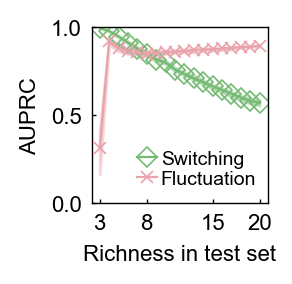

In [ ]:
plot_swi = df_swi.groupby("test_richness")["AUPRC"].agg(mean="mean", min="min", max="max").reset_index()
plot_flu = df_flu.groupby("test_richness")["AUPRC"].agg(mean="mean", min="min", max="max").reset_index()

plt.figure(figsize=(1.1,1.1), dpi=200)

# Colors
color_swi = "#75ba72"
color_flu = "#eaa2ab"

# ---------- Switching ----------
plt.plot(
    plot_swi["test_richness"],
    plot_swi["mean"],
    color=color_swi,
    marker='D',
    markersize=5,
    markerfacecolor='none',
    markeredgewidth=0.6,
    linewidth=0.8,
    label=r"Switching"
)

poly = plt.fill_between(
    plot_swi["test_richness"],
    plot_swi["min"],
    plot_swi["max"],
    color=color_swi,
    alpha=0.4
)
poly.set_rasterized(True)

# ---------- Fluctuation ----------
plt.plot(
    plot_flu["test_richness"],
    plot_flu["mean"],
    color=color_flu,
    marker='x',
    markersize=4,
    markerfacecolor='none',
    markeredgewidth=0.6,
    linewidth=0.8,
    label=r"Fluctuation"
)

poly = plt.fill_between(
    plot_flu["test_richness"],
    plot_flu["min"],
    plot_flu["max"],
    color=color_flu,
    alpha=0.4
)
poly.set_rasterized(True)

plt.xlabel("Richness in test set")
plt.ylabel(r"AUPRC")
plt.xticks([3, 8, 15, 20])
plt.ylim(0,1)

plt.tick_params(direction='in')
plt.grid(False)

plt.legend(
    frameon=False,
    fontsize=7,
    handlelength=1.0,   # legend line length
    handletextpad=0.2,  # spacing between marker and text
    labelspacing=0.1,   # vertical spacing between legend entries
    #borderaxespad=2.5,   # distance between legend and axes boundary
    bbox_to_anchor=(0.16, 0.4)
)

plt.subplots_adjust(
    left=0.18,
    right=0.98,
    bottom=0.18,
    top=0.98
)

plt.savefig(
    f"all_Richness_AUPRC_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches="tight",
    transparent=True
)

plt.show()
